<a href="https://colab.research.google.com/github/intanoktavianipresia/Studi_Kasus_Deep_Learning/blob/main/Sesi_4_Machine_Learning_Prediksi_Kualitas_Udara.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Library berhasil disiapkan.

Ukuran dataset awal: (9471, 17)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN



Jumlah data setelah preprocessing: 7674
Jumlah fitur: 12
Jumlah nilai kosong: 0


,PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888



Jumlah data training: 6139
Jumlah data testing: 1535

Model Random Forest berhasil dilatih.

Hasil evaluasi model:


,Metrik,Nilai
0,MAE,0.244007
1,RMSE,0.389844
2,R²,0.927034


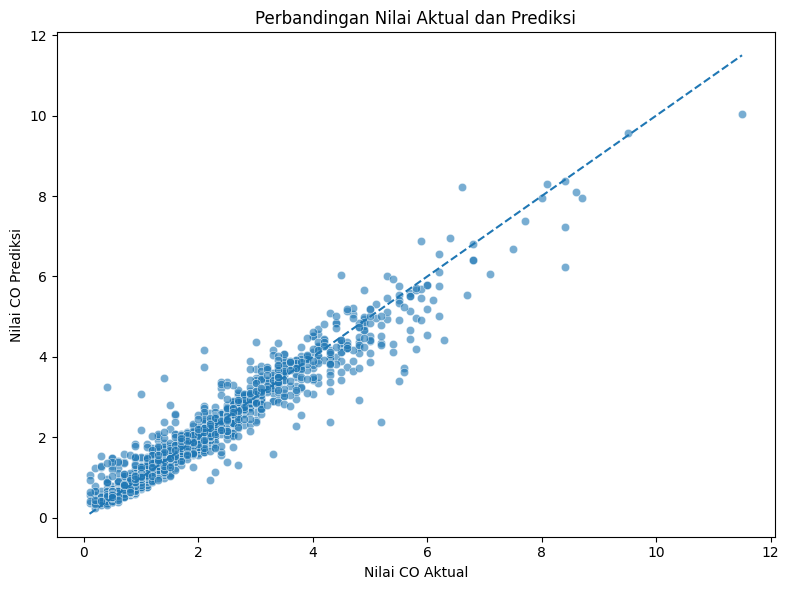


10 fitur terpenting:


,Fitur,Importance
3,PT08.S2(NMHC),0.605616
2,C6H6(GT),0.206010
4,NOx(GT),0.084515
0,PT08.S1(CO),0.023629
6,NO2(GT),0.021358
9,T,0.014545
8,PT08.S5(O3),0.010552
5,PT08.S3(NOx),0.009040
7,PT08.S4(NO2),0.008092
10,RH,0.007529


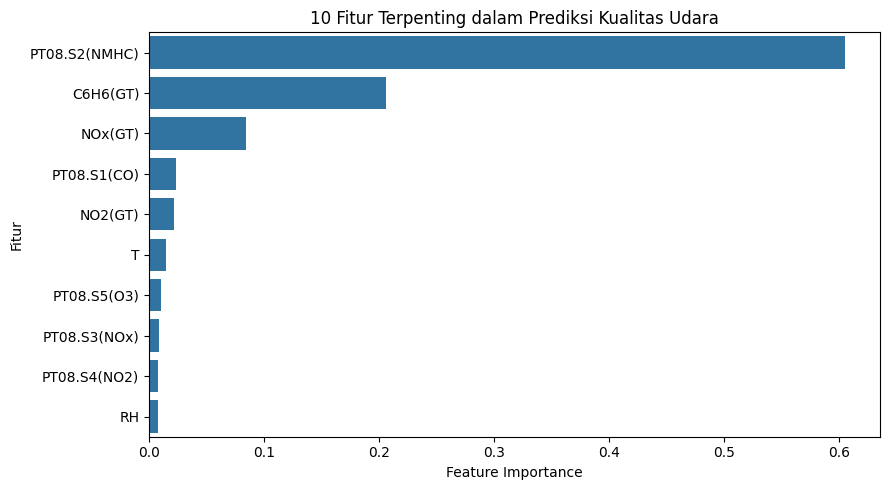


KESIMPULAN
Studi kasus ini menerapkan Machine Learning untuk memprediksi konsentrasi karbon monoksida (CO) menggunakan dataset kualitas udara dari UCI Machine Learning Repository.

MAE  : 0.2440
RMSE : 0.3898
R²   : 0.9270

Model menjelaskan sebagian variasi target pada data pengujian. Nilai MAE, RMSE, dan R² perlu dilihat bersama untuk menilai kinerja model.

Catatan: hasil prediksi merupakan estimasi berdasarkan data, bukan pengukuran kualitas udara secara langsung.


In [1]:
# ============================================================
# STUDI KASUS: PREDIKSI KUALITAS UDARA MENGGUNAKAN MACHINE LEARNING
# Dataset asli: UCI Machine Learning Repository
# ============================================================

# SESI 1 - IMPORT LIBRARY
import requests
import zipfile
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Library berhasil disiapkan.")

# SESI 2 - MENGAMBIL DATASET ASLI
url = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    nama_file = [
        nama for nama in z.namelist()
        if nama.lower().endswith(".csv")
        and "airquality" in nama.lower()
    ]

    if not nama_file:
        raise FileNotFoundError("File CSV dataset tidak ditemukan.")

    with z.open(nama_file[0]) as file:
        df = pd.read_csv(file, sep=";", decimal=",")

print("\nUkuran dataset awal:", df.shape)
display(df.head())

# SESI 3 - PREPROCESSING DATA
df = df.drop(columns=["Date", "Time"], errors="ignore")
df = df.apply(pd.to_numeric, errors="coerce")
df = df.replace(-200, np.nan)
df = df.dropna(axis=1, how="all")

target = "CO(GT)"

if target not in df.columns:
    raise ValueError(f"Kolom target {target} tidak ditemukan.")

df = df.dropna(subset=[target])

X = df.drop(columns=[target]).dropna(axis=1, how="all")
y = df[target]

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

# Hilangkan fitur yang tidak memiliki nilai valid
X = X.dropna(axis=1, how="all")

print("\nJumlah data setelah preprocessing:", len(X))
print("Jumlah fitur:", X.shape[1])
print("Jumlah nilai kosong:", int(X.isna().sum().sum()))

display(X.head())

# SESI 4 - MEMBAGI DATA
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nJumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

# SESI 5 - MELATIH MODEL MACHINE LEARNING
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("\nModel Random Forest berhasil dilatih.")

# SESI 6 - EVALUASI MODEL
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

hasil = pd.DataFrame({
    "Metrik": ["MAE", "RMSE", "R²"],
    "Nilai": [mae, rmse, r2]
})

print("\nHasil evaluasi model:")
display(hasil)

# SESI 7 - VISUALISASI AKTUAL VS PREDIKSI
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)

batas_min = min(y_test.min(), y_pred.min())
batas_max = max(y_test.max(), y_pred.max())

plt.plot(
    [batas_min, batas_max],
    [batas_min, batas_max],
    linestyle="--"
)

plt.xlabel("Nilai CO Aktual")
plt.ylabel("Nilai CO Prediksi")
plt.title("Perbandingan Nilai Aktual dan Prediksi")
plt.tight_layout()
plt.show()

# SESI 8 - ANALISIS FITUR TERPENTING
importance = pd.DataFrame({
    "Fitur": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\n10 fitur terpenting:")
display(importance.head(10))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Fitur"
)

plt.title("10 Fitur Terpenting dalam Prediksi Kualitas Udara")
plt.xlabel("Feature Importance")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

# SESI 9 - KESIMPULAN
print("\n" + "=" * 55)
print("KESIMPULAN")
print("=" * 55)

print(
    "Studi kasus ini menerapkan Machine Learning untuk "
    "memprediksi konsentrasi karbon monoksida (CO) menggunakan "
    "dataset kualitas udara dari UCI Machine Learning Repository."
)

print(
    f"\nMAE  : {mae:.4f}"
    f"\nRMSE : {rmse:.4f}"
    f"\nR²   : {r2:.4f}"
)

if r2 > 0:
    print(
        "\nModel menjelaskan sebagian variasi target pada data pengujian. "
        "Nilai MAE, RMSE, dan R² perlu dilihat bersama untuk menilai "
        "kinerja model."
    )
else:
    print(
        "\nModel belum menunjukkan kemampuan prediksi yang baik pada "
        "data pengujian. Model atau fitur perlu dievaluasi lebih lanjut."
    )

print(
    "\nCatatan: hasil prediksi merupakan estimasi berdasarkan data, "
    "bukan pengukuran kualitas udara secara langsung."
)